# Progetto d'esame: classificazione del tumore al seno con Machine Learning e SHAP

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — UCI Machine Learning Repository  
**Scopo:** esperimento didattico; non è uno strumento diagnostico clinico.


**Fonte primaria del dataset (prevista dalla traccia):** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic  
**Attribuzione:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)*, UCI ML Repository. DOI: 10.24432/C5DW2B. Licenza CC BY 4.0.

## 1. Librerie e impostazioni

In [ ]:
import sys
import subprocess
import importlib.util
if importlib.util.find_spec("shap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap"])

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)
print("Versione scikit-learn:", __import__("sklearn").__version__)
print("Versione SHAP:", shap.__version__)

Versione scikit-learn: 1.6.1
Versione SHAP: 0.52.0


## 2. Dataset ed esplorazione

In [ ]:
original = load_breast_cancer(as_frame=True)
X = original.data.copy()
y = (original.target == 0).astype(int)  # 1 = maligno; 0 = benigno
class_names = ["Benigno (0)", "Maligno (1)"]

df = X.copy()
df["diagnosi_maligna"] = y
print("Dimensione:", X.shape)
print("Classi (0=benigno, 1=maligno):")
print(y.value_counts().sort_index())
print("Valori mancanti:", int(X.isna().sum().sum()))
print("Duplicati completi:", int(df.duplicated().sum()))
display(df.head())
display(X.describe().T.head(10))

Dimensione: (569, 30)
Classi (0=benigno, 1=maligno):
target
0    357
1    212
Name: count, dtype: int64
Valori mancanti: 0
Duplicati completi: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosi_maligna
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


## 3. Separazione dei dati: train/validation/test

In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEED, stratify=y_dev
)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))
print("Train classi:", y_train.value_counts().sort_index().to_dict())
print("Validation classi:", y_val.value_counts().sort_index().to_dict())
print("Test classi:", y_test.value_counts().sort_index().to_dict())

Train: 341 | Validation: 114 | Test: 114
Train classi: {0: 214, 1: 127}
Validation classi: {0: 71, 1: 43}
Test classi: {0: 72, 1: 42}


## 4. PCA: analisi delle feature e visualizzazione

Varianza PC1: 0.4563
Varianza PC2: 0.1817
Varianza prime due PC: 0.638
Componenti per >=95% di varianza: 10


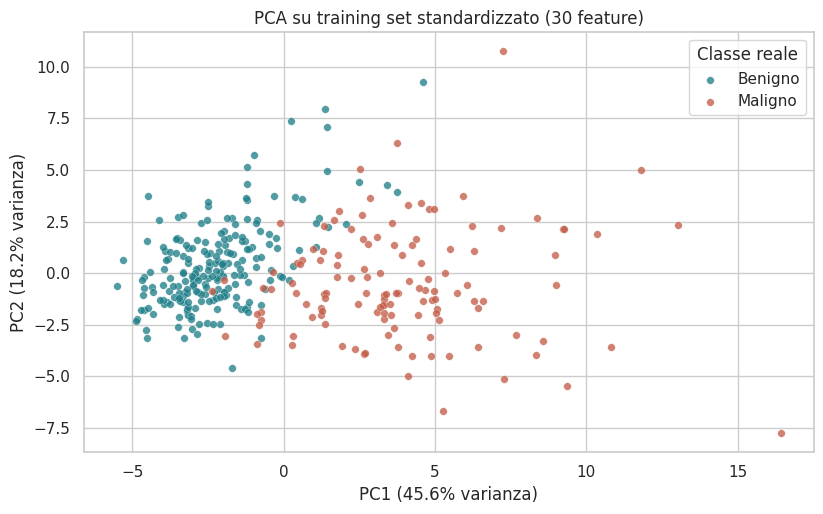

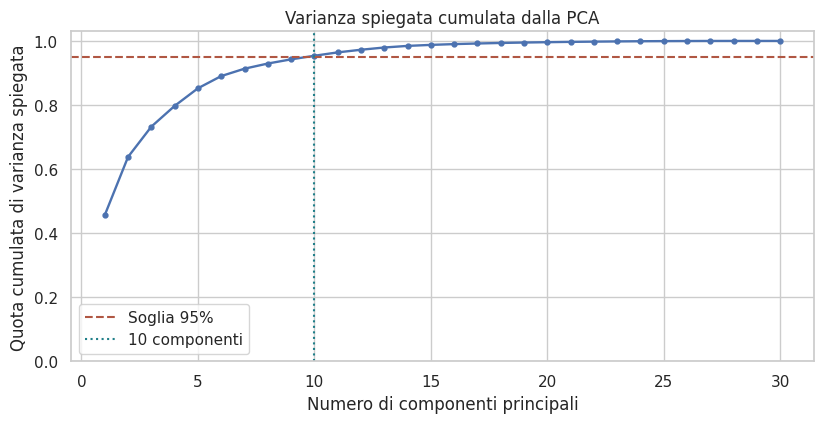

Feature con i pesi assoluti maggiori in PC1:


,peso assoluto PC1
mean concave points,0.256452
mean concavity,0.254621
worst concave points,0.247441
mean compactness,0.238563
worst perimeter,0.235696
worst radius,0.226769
mean perimeter,0.226060


In [ ]:
scaler_pca = StandardScaler().fit(X_train)
X_train_scaled = scaler_pca.transform(X_train)
pca2 = PCA(n_components=2).fit(X_train_scaled)
X_train_pca = pca2.transform(X_train_scaled)
pca_full = PCA().fit(X_train_scaled)
var_due_pc = float(pca2.explained_variance_ratio_.sum())
n95 = int(np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.95) + 1)
print("Varianza PC1:", round(pca2.explained_variance_ratio_[0], 4))
print("Varianza PC2:", round(pca2.explained_variance_ratio_[1], 4))
print("Varianza prime due PC:", round(var_due_pc, 4))
print("Componenti per >=95% di varianza:", n95)

fig, ax = plt.subplots(figsize=(8.4, 5.3))
for cls, text_label, color in [(0, 'Benigno', '#207f89'), (1, 'Maligno', '#c35e49')]:
    mask = y_train.to_numpy() == cls
    ax.scatter(X_train_pca[mask,0], X_train_pca[mask,1], s=30, alpha=.78,
               label=text_label, c=color, edgecolors='white', linewidths=.25)
ax.set(xlabel=f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% varianza)',
       ylabel=f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% varianza)',
       title='PCA su training set standardizzato (30 feature)')
ax.legend(title='Classe reale')
fig.tight_layout()
fig.savefig(OUTPUT/'pca_scatter.png', dpi=170, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.plot(range(1, X.shape[1]+1), np.cumsum(pca_full.explained_variance_ratio_),
        marker='o', markersize=3.5, linewidth=1.7)
ax.axhline(0.95, color='#b05743', linestyle='--', label='Soglia 95%')
ax.axvline(n95, color='#207f89', linestyle=':', label=f'{n95} componenti')
ax.set(xlabel='Numero di componenti principali', ylabel='Quota cumulata di varianza spiegata',
       title='Varianza spiegata cumulata dalla PCA', ylim=(0, 1.03))
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT/'pca_varianza.png', dpi=170, bbox_inches='tight')
plt.show()

pca_weights = pd.Series(pca2.components_[0], index=X.columns)
print('Feature con i pesi assoluti maggiori in PC1:')
display(pca_weights.abs().sort_values(ascending=False).head(7).to_frame('peso assoluto PC1'))

## 5. Tre algoritmi di classificazione e scelta degli iperparametri

In [ ]:
grids = {
    'Logistic Regression': list(ParameterGrid({'C': [0.1, 1.0, 10.0]})),
    'KNN': list(ParameterGrid({'n_neighbors': [3, 5, 7, 11]})),
    'Random Forest': list(ParameterGrid({'max_depth': [None, 5, 10]})),
}

def make_model(name, params):
    if name == 'Logistic Regression':
        return Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(C=params['C'], max_iter=4000, random_state=SEED))
        ])
    if name == 'KNN':
        return Pipeline([
            ('scaler', StandardScaler()),
            ('model', KNeighborsClassifier(n_neighbors=params['n_neighbors']))
        ])
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=200, max_depth=params['max_depth'],
                                      random_state=SEED, n_jobs=-1)
    raise ValueError(name)

val_records = []
selected = {}
for name, candidates in grids.items():
    best_rank, best_params = (-1, -1, -1), None
    for params in candidates:
        model = make_model(name, params)
        model.fit(X_train, y_train)
        pred = model.predict(X_val)
        prob = model.predict_proba(X_val)[:, 1]
        f1 = float(f1_score(y_val, pred, zero_division=0))
        auc = float(roc_auc_score(y_val, prob))
        acc = float(accuracy_score(y_val, pred))
        val_records.append(dict(modello=name, parametri=str(params), f1_val=f1,
                                roc_auc_val=auc, accuracy_val=acc))
        rank = (f1, auc, acc)
        if rank > best_rank:
            best_rank, best_params = rank, params
    selected[name] = best_params

val_table = pd.DataFrame(val_records)
val_table.to_csv(OUTPUT/'ricerca_validazione.csv', index=False)
display(val_table.round(4))
print('Configurazioni scelte sul validation set:')
for key, param in selected.items():
    print(f'  {key}: {param}')

,modello,parametri,f1_val,roc_auc_val,accuracy_val
0,Logistic Regression,{'C': 0.1},0.9762,0.9951,0.9825
1,Logistic Regression,{'C': 1.0},0.9655,0.9957,0.9737
2,Logistic Regression,{'C': 10.0},0.9545,0.9957,0.9649
3,KNN,{'n_neighbors': 3},0.9524,0.9949,0.9649
4,KNN,{'n_neighbors': 5},0.9639,0.9948,0.9737
5,KNN,{'n_neighbors': 7},0.9639,0.9961,0.9737
6,KNN,{'n_neighbors': 11},0.9639,0.9930,0.9737
7,Random Forest,{'max_depth': None},0.9647,0.9916,0.9737
8,Random Forest,{'max_depth': 5},0.9647,0.9931,0.9737
9,Random Forest,{'max_depth': 10},0.9647,0.9916,0.9737


Configurazioni scelte sul validation set:
  Logistic Regression: {'C': 0.1}
  KNN: {'n_neighbors': 7}
  Random Forest: {'max_depth': 5}


## 6. Valutazione finale sul test

In [ ]:
trained = {}
results = []
preds, probs = {}, {}
for name, best_params in selected.items():
    model = make_model(name, best_params)
    model.fit(X_dev, y_dev)       # refit su train + validation, mai su test
    yp = model.predict(X_test)
    ps = model.predict_proba(X_test)[:, 1]
    trained[name] = model
    preds[name], probs[name] = yp, ps
    cm = confusion_matrix(y_test, yp, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()
    results.append({
        'Modello': name,
        'Accuracy': float(accuracy_score(y_test, yp)),
        'Precision': float(precision_score(y_test, yp, zero_division=0)),
        'Recall': float(recall_score(y_test, yp, zero_division=0)),
        'F1': float(f1_score(y_test, yp, zero_division=0)),
        'ROC AUC': float(roc_auc_score(y_test, ps)),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)
    })
metrics = pd.DataFrame(results).sort_values(['F1', 'ROC AUC'], ascending=False).reset_index(drop=True)
metrics.to_csv(OUTPUT/'metriche_test.csv', index=False)
display(metrics.round(4))
print('Miglior modello per F1 sul test (solo descrittivo, NON selezionato sul test):', metrics.iloc[0]['Modello'])

,Modello,Accuracy,Precision,Recall,F1,ROC AUC,TN,FP,FN,TP
0,Logistic Regression,0.9825,1.0000,0.9524,0.9756,0.9977,72,0,2,40
1,Random Forest,0.9649,1.0000,0.9048,0.9500,0.9947,72,0,4,38
2,KNN,0.9561,0.9744,0.9048,0.9383,0.9825,71,1,4,38


Miglior modello per F1 sul test (solo descrittivo, NON selezionato sul test): Logistic Regression


## 7. Matrici di confusione e curve ROC

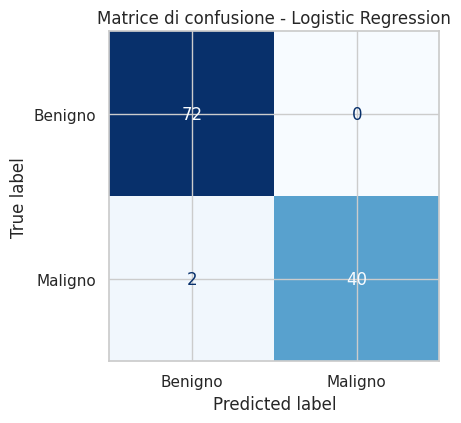

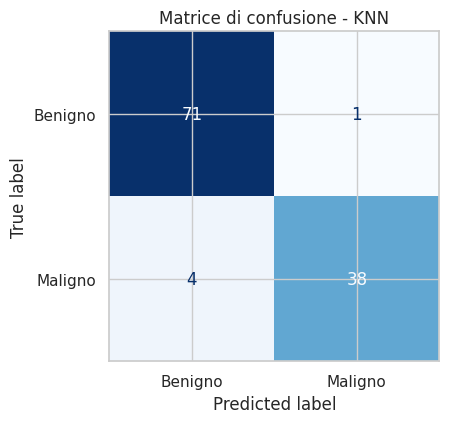

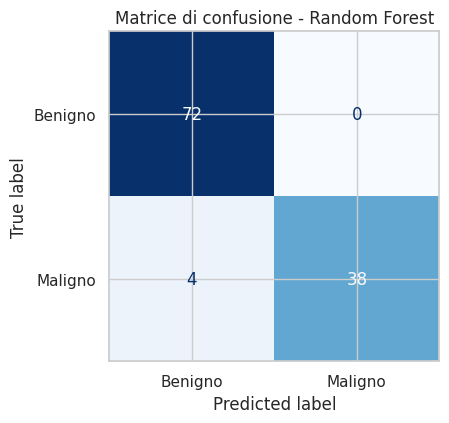

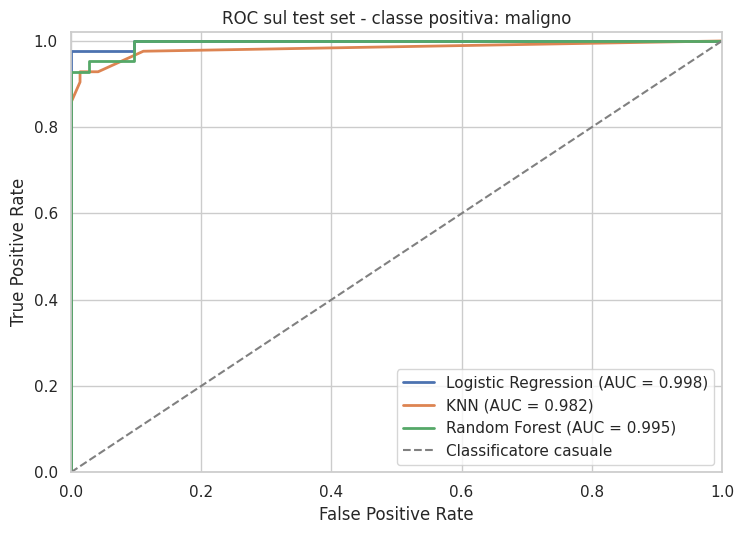

In [ ]:
for name, yp in preds.items():
    cm = confusion_matrix(y_test, yp, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5.4, 4.4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benigno', 'Maligno'])
    disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title('Matrice di confusione - ' + name)
    fig.tight_layout()
    slug = name.lower().replace(' ', '_')
    fig.savefig(OUTPUT/f'confusion_{slug}.png', dpi=170, bbox_inches='tight')
    plt.show()

fig, ax = plt.subplots(figsize=(7.6, 5.5))
for name in ['Logistic Regression', 'KNN', 'Random Forest']:
    fpr, tpr, thresholds = roc_curve(y_test, probs[name])
    auc = roc_auc_score(y_test, probs[name])
    ax.plot(fpr, tpr, linewidth=2.0, label=f'{name} (AUC = {auc:.3f})')
ax.plot([0,1], [0,1], '--', color='gray', label='Classificatore casuale')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='ROC sul test set - classe positiva: maligno', xlim=(0,1), ylim=(0,1.02))
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(OUTPUT/'roc_confronto.png', dpi=170, bbox_inches='tight')
plt.show()

## 8. Explainable AI: SHAP sulla Random Forest (opzione 5b)

Scarto massimo tra somma SHAP e probabilità prevista: 0.0
Prime 10 feature secondo media |SHAP| sul test:


,media |SHAP|
worst perimeter,0.067671
worst area,0.059945
worst concave points,0.057873
worst radius,0.044403
mean concave points,0.043671
mean area,0.022971
mean radius,0.022782
mean concavity,0.022516
worst concavity,0.022060
mean perimeter,0.021131


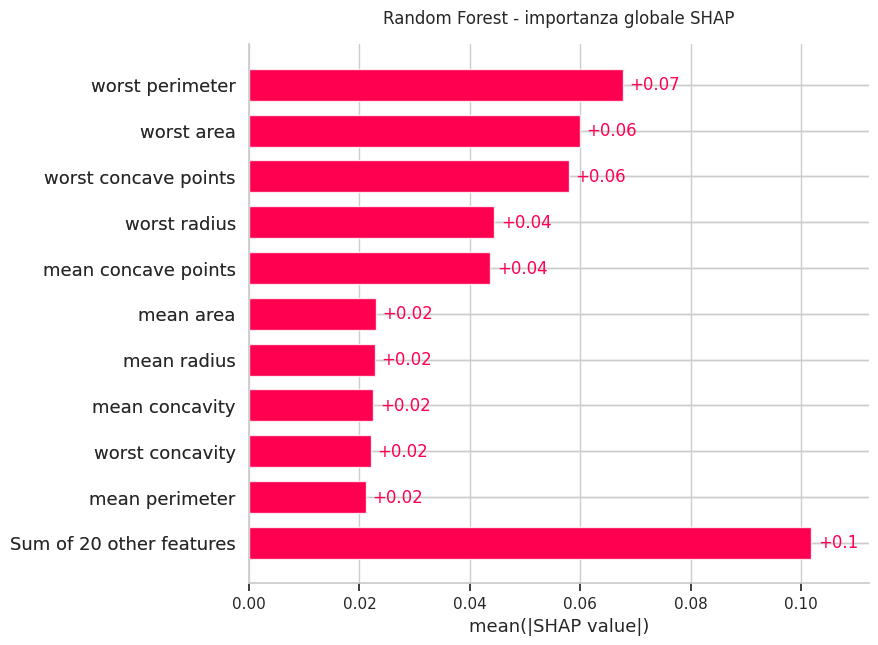

Caso locale sul test: indice 1 | valore reale: 1 | probabilità maligno prevista: 0.9998


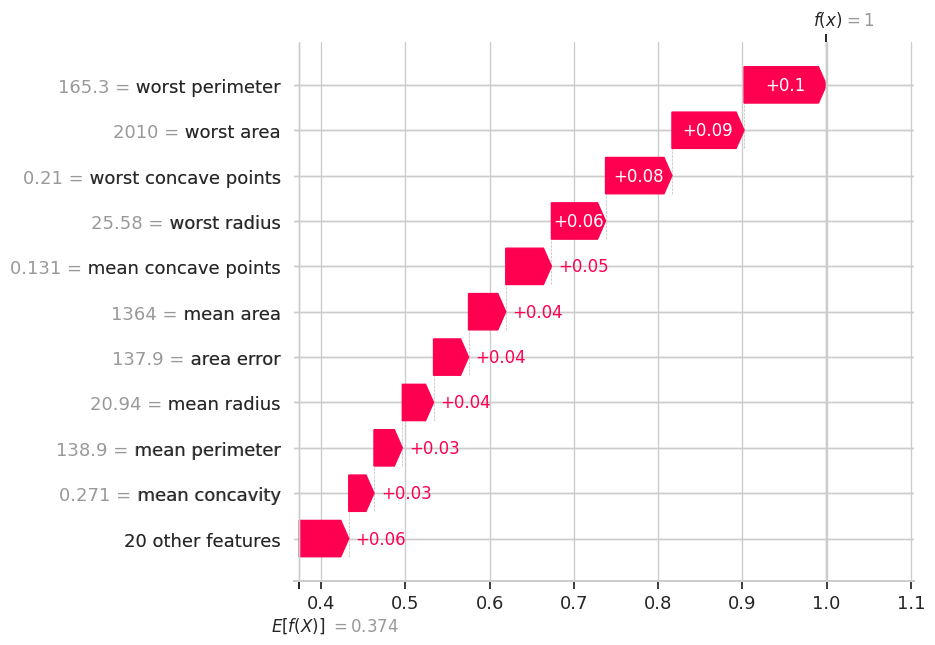

In [ ]:
rf = trained['Random Forest']
explainer = shap.TreeExplainer(rf)
shap_output = explainer(X_test)
# Per scikit-learn RF binaria, SHAP corrente fornisce [esempi, feature, 2 classi].
if len(shap_output.values.shape) == 3:
    shap_malignant = shap_output[:, :, 1]
else:
    shap_malignant = shap_output

# Controllo della proprietà di additività, ove la scala di output è la probabilità.
shap_sum = np.asarray(shap_malignant.base_values) + np.asarray(shap_malignant.values).sum(axis=1)
max_shap_difference = float(np.max(np.abs(shap_sum - rf.predict_proba(X_test)[:, 1])))
print('Scarto massimo tra somma SHAP e probabilità prevista:', round(max_shap_difference, 10))

shap_importance = pd.Series(np.abs(shap_malignant.values).mean(axis=0), index=X.columns)
shap_top = shap_importance.sort_values(ascending=False).head(10)
print('Prime 10 feature secondo media |SHAP| sul test:')
display(shap_top.to_frame('media |SHAP|'))

plt.figure()
shap.plots.bar(shap_malignant, max_display=11, show=False)
plt.title('Random Forest - importanza globale SHAP', pad=15)
plt.gcf().savefig(OUTPUT/'shap_importanza.png', dpi=170, bbox_inches='tight')
plt.show()

maligni_veri_positivi = np.flatnonzero((y_test.to_numpy() == 1) & (preds['Random Forest'] == 1))
case_idx = int(maligni_veri_positivi[0]) if len(maligni_veri_positivi) else 0
print('Caso locale sul test: indice', case_idx,
      '| valore reale:', int(y_test.iloc[case_idx]),
      '| probabilità maligno prevista:', round(float(rf.predict_proba(X_test.iloc[[case_idx]])[0,1]), 4))
shap.plots.waterfall(shap_malignant[case_idx], max_display=11, show=False)
plt.gcf().savefig(OUTPUT/'shap_caso_locale.png', dpi=170, bbox_inches='tight')
plt.show()

## 9. Esportazione dei risultati e discussione

In [ ]:
payload = {
    'dataset': 'Breast Cancer Wisconsin (Diagnostic), UCI id 17; caricato via scikit-learn',
    'n_samples': int(len(X)), 'n_features': int(X.shape[1]),
    'n_benign': int((y==0).sum()), 'n_malignant': int((y==1).sum()),
    'n_missing': int(X.isna().sum().sum()),
    'train_size': int(len(X_train)), 'validation_size': int(len(X_val)),
    'test_size': int(len(X_test)),
    'pca_2_variance': var_due_pc,
    'pca_pc1_variance': float(pca2.explained_variance_ratio_[0]),
    'pca_pc2_variance': float(pca2.explained_variance_ratio_[1]),
    'pca_n95': n95,
    'pca_pc1_top_features': pca_weights.abs().sort_values(ascending=False).head(7).index.tolist(),
    'selected_hyperparameters': selected,
    'metrics': results,
    'shap_top_features': [{'name': a, 'mean_abs_shap': float(b)} for a,b in shap_top.items()],
    'shap_local_case_index': case_idx,
    'shap_local_true_class': int(y_test.iloc[case_idx]),
    'shap_local_predicted_probability': float(rf.predict_proba(X_test.iloc[[case_idx]])[0,1]),
    'shap_max_additivity_error': max_shap_difference,
    'seed': SEED,
}
with open(OUTPUT/'results.json', 'w', encoding='utf-8') as f:
    json.dump(payload, f, ensure_ascii=False, indent=2)
print('Esportati i file in:', OUTPUT.resolve())
print('Questa è una dimostrazione didattica: le predizioni non vanno utilizzate per decisioni cliniche.')

Esportati i file in: /content/outputs
Questa è una dimostrazione didattica: le predizioni non vanno utilizzate per decisioni cliniche.
